# **IDO (Simulaciones)**

In [38]:
# Importación de librerías necesarias
import numpy as np
import matplotlib.pyplot as plt
import random
from scipy import stats

In [39]:
import math
import numpy as np
import matplotlib.pyplot as plt
import random

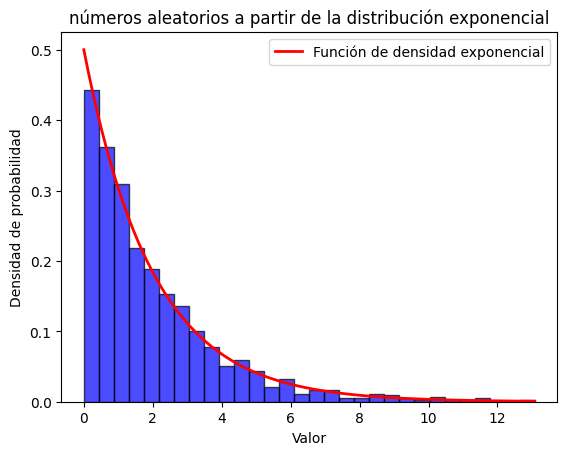

In [45]:
# Parámetro de intensidad
lambda_parametro = 0.5

def exponencial_transformada_inversa(lambda_param):
    """
    Genera variables aleatorias exponenciales usando el método de la transformada inversa.
    """
    # Generamos un número aleatorio con distribución uniforme en [0, 1)
    U = random.random()

    # La variable aleatoria que se obtiene a través de la transformada inversa
    X = -math.log(1 - U) / lambda_param

    return X

# Tamaño de número aleatorios a generar
num_muestra = 1000

# Generar números aleatorios a partir de la distribución exponencial.
numeros_aleatorios_exponenciales = [exponencial_transformada_inversa(lambda_parametro) for _ in range(num_muestra)]

# Histograma de los números aleatorios.
plt.hist(numeros_aleatorios_exponenciales, bins=30, density=True, alpha=0.7, color='blue', edgecolor='black')

# Graficar la función de densidad exponencial teórica y comparar
x = np.linspace(0, max(numeros_aleatorios_exponenciales), 100)
pdf = lambda_parametro * np.exp(-lambda_parametro * x)
plt.plot(x, pdf, 'r-', lw=2, label='Función de densidad exponencial')

plt.title('números aleatorios a partir de la distribución exponencial')
plt.xlabel('Valor')
plt.ylabel('Densidad de probabilidad')
plt.legend(loc='best')

plt.show()

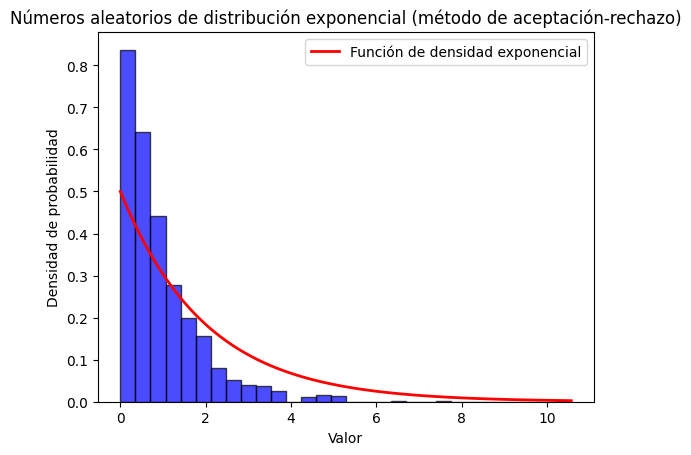

In [43]:
# Parámetro de intensidad
lambda_parametro = 0.5

# Valor máximo de la distribución exponencial (elegido para asegurar la aceptación)
M = 1 / lambda_parametro

def exponencial_aceptacion (lambda_parametro, M):
    while True:
        # Genere un número aleatorio a partir de la distribución exponencial con el parámetro lambda_param
        x = -math.log(1 - random.random()) / lambda_parametro

        # Generar un número aleatorio uniforme para aceptación/rechazo
        u = random. random ()

        # Aceptar el valor generado si cae por debajo de la curva exponencial.
        if u < lambda_parametro * math.exp(-lambda_parametro * x) / M:

            return x

# Número de números aleatorios a generar
num_muestra = 1000

# Genere números aleatorios a partir de la distribución exponencial utilizando el método de aceptación-rechazo
numeros_exponencial = [exponencial_aceptacion(lambda_parametro, M) for _ in range(num_muestra)]

# Crear un histograma
plt.hist (numeros_exponencial, bins=30, density=True, alpha=0.7, color='blue', edgecolor='black')

# Graficar la función de densidad exponencial teórica y comparar
x = np. linspace(0, max (numeros_exponencial), 100)
pdf = lambda_parametro * np.exp(-lambda_parametro * x)
plt.plot(x, pdf, 'r-', lw=2, label='Función de densidad exponencial')
plt.title('Números aleatorios de distribución exponencial (método de aceptación-rechazo)')
plt.xlabel('Valor')
plt.ylabel( 'Densidad de probabilidad')
plt. legend (loc='best')

plt.show()

In [28]:
import pandas as pd

Text(1.0, 0.03, 'Aceptación')

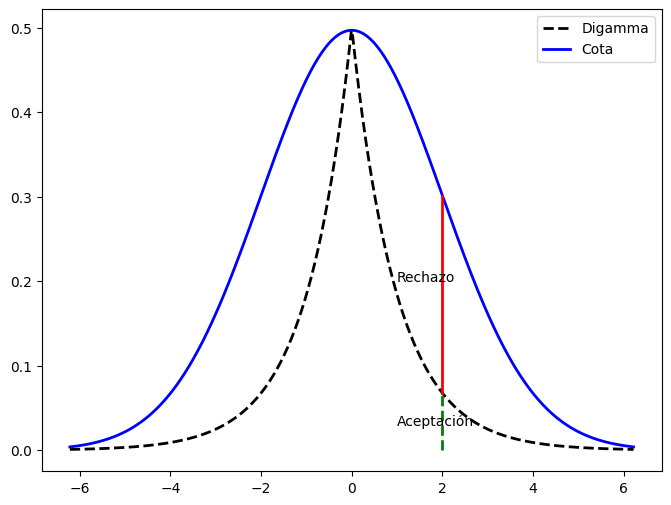

In [44]:
dg = stats.dgamma(a=1) # Distribución digamma
norm = stats.norm(loc=0, scale=2) # distribución normal

# Generar muestras para PDF
x = np.linspace(min(dg.ppf(0.001), norm.ppf (0.001)),
                max(dg.ppf(0.999), norm.ppf (0.999)), 1000)

dg_muestra = dg.pdf (x)
norm_muestra = norm.pdf (x)

# Encuentrar la constante de escala para la envolvente
M = max(dg_muestra / norm_muestra)

# Gráficas
df = pd. DataFrame({'Digamma': dg_muestra, 'Cota': M * norm_muestra}, index=x)
ax = df.plot (style=['--','-'], color=['black', 'blue'],
              figsize=(8,6), linewidth=2.0)
ax.plot((2, 2), (0, dg.pdf (2)),'g--', linewidth=2.0)
ax.plot((2, 2), (dg.pdf(2), M * norm.pdf(2)), 'r-', linewidth=2.0)
ax.text(1.0, 0.20,'Rechazo')
ax. text (1.0, 0.03, 'Aceptación')